In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

from numpy.lib.stride_tricks import sliding_window_view

I0000 00:00:1795776848.173829 1177340 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795776848.215071 1177340 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795776849.007927 1177340 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Import Data

Text(0.5, 0.98, 'All Data')

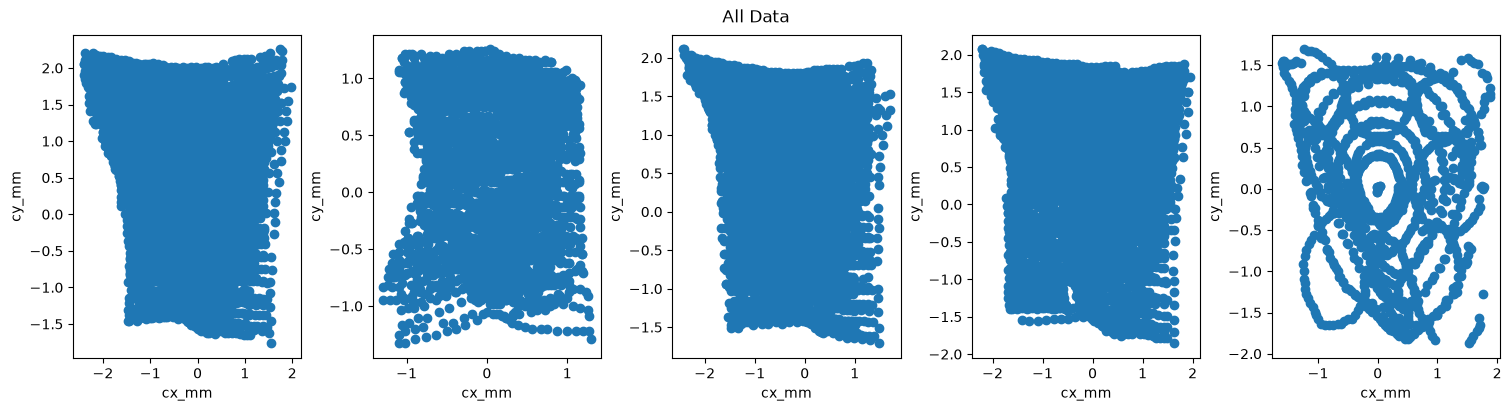

In [3]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_4 = pd.read_csv("processed_data/pred_data.csv", dtype="float32")

#remove nans
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_3 = data_3.dropna()

data_list = [ data_1, data_4, data_3, data_0,  data_2 ]

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2>Concatenate

In [4]:
all_data = pd.concat(data_list, ignore_index=True)

In [5]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3, constrained_layout=True)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

<h3>Windows

This is a normal MLP but the input is a window

In [6]:
#function from https://machinelearningmastery.com/convert-time-series-supervised-learning-problem-python/
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	"""
	Frame a time series as a supervised learning dataset.
	Arguments:
		data: Sequence of observations as a list or NumPy array.
		n_in: Number of lag observations as input (X).
		n_out: Number of observations as output (y).
		dropnan: Boolean whether or not to drop rows with NaN values.
	Returns:
		Pandas DataFrame of series framed for supervised learning.
	"""
	n_vars = 1 if type(data) is list else data.shape[1]
	df = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

In [7]:
dataset = all_data[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined

# values = dataset.values

window_size = 10

cxcy_window = series_to_supervised(dataset,window_size,1)

# cols_to_drop = cxcy_window.filter(regex="var3|var4|var5.*")
# inputs = cxcy_window.drop(list(cols_to_drop), axis=1)
 #change input window to include all motor values
# cxcy_window = cxcy_window.rename(columns={"var3(t)": "s0(t)", "var4(t)": "s1(t)", "var5(t)": "s2(t)"})
# outputs = cxcy_window[["s0(t)","s1(t)"]] #calculate s2(t) from s2 = -(s0 + s1)

# print(all_data["s2"][10:] == -(outputs["s0(t)"] + outputs["s1(t)"]))
outputs = cxcy_window[["var3(t)","var4(t)"]] #, "var5(t)" #don't predict s2 but keep it in training data
inputs = cxcy_window.drop(["var3(t)","var4(t)", "var5(t)"], axis=1)

inputs["cx_diff"] = inputs["var1(t)"].diff()
inputs["cy_diff"] = inputs["var2(t)"].diff()

inputs = inputs[1:]

display(cxcy_window.head(1))
display(inputs.head(2))
display(outputs.head(1))


,var1(t-10),var2(t-10),var3(t-10),var4(t-10),var5(t-10),var1(t-9),var2(t-9),var3(t-9),var4(t-9),var5(t-9),...,var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var1(t),var2(t),var3(t),var4(t),var5(t)
10,0.009091,0.0,0.0,0.0,0.0,-0.009091,0.0,0.0,0.0,0.0,...,0.863636,1.6,6144.0,-5289.0,-855.0,0.736364,1.6,6144.0,-4846.0,-1298.0


,var1(t-10),var2(t-10),var3(t-10),var4(t-10),var5(t-10),var1(t-9),var2(t-9),var3(t-9),var4(t-9),var5(t-9),...,var5(t-2),var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var1(t),var2(t),cx_diff,cy_diff
11,-0.009091,0.000000,0.0,0.0,0.0,1.972727,1.745455,6144.0,-8393.0,2249.0,...,-855.0,0.736364,1.6,6144.0,-4846.0,-1298.0,0.572727,1.600000,-0.163636,0.000000
12,1.972727,1.745455,6144.0,-8393.0,2249.0,1.827273,1.727273,6144.0,-7949.0,1805.0,...,-1298.0,0.572727,1.6,6144.0,-4402.0,-1742.0,0.390909,1.581818,-0.181818,-0.018182


,var3(t),var4(t)
10,6144.0,-4846.0


<h2>TimeSeriesSplit

In [8]:
def plot_loss_and_mae(history):
  fig, axs = plt.subplots(1, 2, figsize=(10,5), constrained_layout=True)
  for i, value in enumerate(['loss', 'mse']):
    subplot = axs[i]
    subplot.plot(history.history[value], label=value)
    subplot.plot(history.history[f'val_{value}'], label=f'val_{value}')
  #   plt.ylim([0, 10])
    subplot.set_xlabel('Epoch')
    subplot.set_ylabel('Error')
    subplot.legend()
    subplot.grid(True)
    subplot.set_title(value)

In [16]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(256, activation='relu'),
            tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dropout(0.05),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mae',
    metrics=['mae', 'mse'])

    return model

def train_model(model, X_train, y_train, epochs=500, patience=30, verbose=0):
    """Train a model with early stopping and learning rate scheduling"""
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=patience,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=50,
            min_lr=1e-7
        )
    ]
    
    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=128,
        verbose=verbose,
        callbacks=callbacks,
        shuffle=False
    )
    
    return history

  Train: index=0 to 2783 
  Test:  index=2784 to 5563
  Train: index=0 to 5563 
  Test:  index=5564 to 8343
  Train: index=0 to 8343 
  Test:  index=8344 to 11123
  Train: index=0 to 11123 
  Test:  index=11124 to 13903
(11124, 54)
(11124, 54)
Epoch 1/1000
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3630 - mae: 0.3630 - mse: 0.2926 - val_loss: 0.2805 - val_mae: 0.2805 - val_mse: 0.1553 - learning_rate: 0.0010
Epoch 2/1000
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2316 - mae: 0.2316 - mse: 0.1061 - val_loss: 0.2216 - val_mae: 0.2216 - val_mse: 0.0856 - learning_rate: 0.0010
Epoch 3/1000
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1990 - mae: 0.1990 - mse: 0.0793 - val_loss: 0.1715 - val_mae: 0.1715 - val_mse: 0.0595 - learning_rate: 0.0010
Epoch 4/1000
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1754 - mae: 0.1754 - mse: 0.0636 - val_loss: 0.1810 - val_mae: 0.1810 - val_mse: 0.0635 - learning_rate: 0.0010
Epoch 5/1000
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 

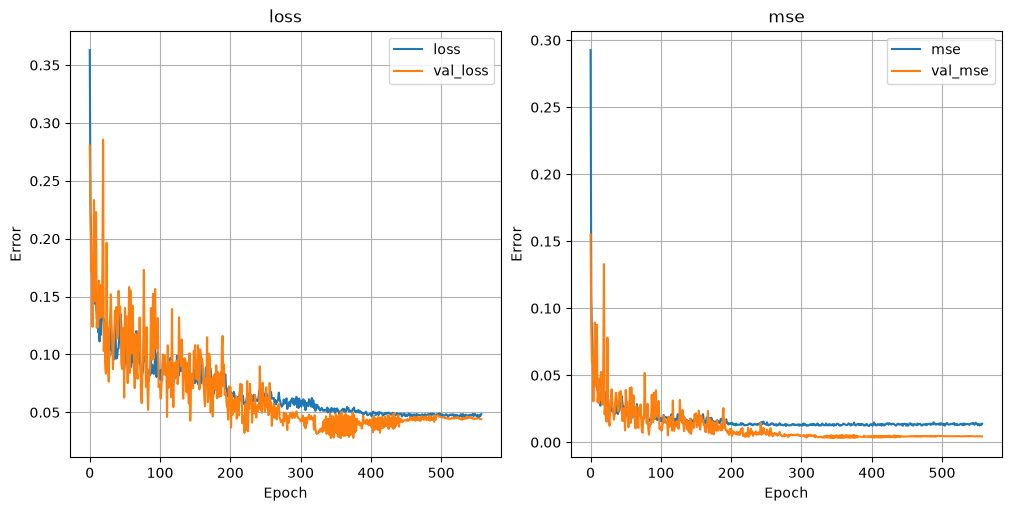

In [17]:

scores = []
train_indices = []
test_indices = []

tscv = TimeSeriesSplit(n_splits=4)
for i, (train_index, test_index) in enumerate(tscv.split(inputs)):

    # print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")

    train_indices = train_index
    test_indices = test_index
    #just want indices of final fold - 80:20 train:test


X_train, X_test = inputs.to_numpy()[train_index], inputs.to_numpy()[test_index]
y_train, y_test = outputs.to_numpy()[train_index], outputs.to_numpy()[test_index]

print(X_train.shape)
print(X_train.shape)
# model.summary() #investigate

scalerX = StandardScaler().fit(X_train)
scalerY = StandardScaler().fit(y_train)

# scalerS = StandardScaler().fit(y_train[:,0])

X_train_scaled = scalerX.transform(X_train)
y_train_scaled = scalerY.transform(y_train)

X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

model = build_nn_model(X_train_scaled.shape[1], y_train_scaled.shape[1])

history = train_model(model, X_train_scaled, y_train_scaled, verbose=1, epochs=1000, patience=200)
min_mae =  min(history.history["mae"])
print("Lowest MAE", min(history.history["mae"]))
# print("Lowest MAE, inverse", scalerS.inverse_transform(min_mae))


y_pred = model.predict(X_test_scaled, verbose=0)

evaluate_model(f"Fold: {i}", y_test_scaled, y_pred, is_scaled=True)

# y_test_inverse = scalerY.inverse_transform(y_test)
y_pred_inverse = scalerY.inverse_transform(y_pred)

y_pred_df = pd.DataFrame(y_pred_inverse)
y_pred_df[2] = -(y_pred_df[0] + y_pred_df[1])

y_test_df = pd.DataFrame(y_test)
y_test_df[2] = -(y_test_df[0] + y_test_df[1])

# for i in range(3): 
#     evaluate_model(f"s{i}", y_test_df[i], y_pred_df[i], is_scaled=False)

# plot_motors(y_test_df.to_numpy(), y_pred_df.to_numpy(), [-10000,10000])

error = mean_squared_error(y_test, y_pred)
scores.append(error)
plot_loss_and_mae(history)

# print("MSE scores for each fold:", scores)

In [11]:
# model.save(f'window_{window_size}_dropout.keras')

<h1>From bot

In [15]:
from joblib import dump, load
dump(scalerX, 'scalerX.bin', compress=True)
dump(scalerY, 'scalerY.bin', compress=True)

['scalerY.bin']

In [13]:
bot_test = pd.read_csv(f"../../../DeltabotController/python/scripts/window_{window_size}_test.csv", header=0, index_col=0)
bot_test.iloc[[-1]]

,var1(t-9),var2(t-9),var3(t-9),var4(t-9),var5(t-9),var1(t-8),var2(t-8),var3(t-8),var4(t-8),var5(t-8),...,var5(t-1),var1(t),var2(t),var3(t),var4(t),var5(t),var1(t+1),var2(t+1),cx_diff,cy_diff
10,-0.084388,0.033755,0.0,443.0,-443.0,-0.135021,0.050633,0.0,887.0,-887.0,...,-3991.0,-0.860759,0.320675,0,4434,-4434,-1.0,0.0,-0.139241,-0.320675


In [14]:
bot_test = pd.read_csv(f"../../../DeltabotController/python/scripts/window_{window_size}_test.csv", header=0, index_col=0)
bot_test.iloc[[-1]]

bot_test_scaled = scalerX.transform(bot_test.iloc[[-1]])

bot_test_pred = model.predict(bot_test_scaled)
bot_test_pred_inverse = scalerY.inverse_transform(bot_test_pred)
bot_test_pred_inverse = np.append(bot_test_pred_inverse, -(bot_test_pred_inverse[:,0] + bot_test_pred_inverse[:,1])) #calculate s2
print(bot_test_pred_inverse.astype("int32")) 


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
[  148  4181 -4330]


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
